# 1 · Grafo sin modelo

**Módulo 1 · Introducción.** El proyecto del módulo es un agente de cálculo simbólico. Esta lección construye su base sin modelo de lenguaje: un grafo que ejecuta el método de Newton. Corre en CPU, sin GPU ni claves.

Se definen las piezas de un grafo de LangGraph (esquema, estado, nodo, reducer y arista), su modelo de ejecución por supersteps y las condiciones para que una ejecución termine. Corresponde a la lección *Simple graph* del curso [Intro to LangGraph](https://academy.langchain.com/courses/intro-to-langgraph) de LangChain Academy.

Requisito: `pip install "langgraph>=1.2"`. Las salidas de este notebook son de langgraph 1.2.17.

In [1]:
from importlib.metadata import version

print("langgraph", version("langgraph"))

langgraph 1.2.17


## 1. El problema

El método de Newton aproxima una raíz de una función derivable $f$ con la iteración

$$x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}.$$

Con $f(x) = x^2 - 2$ y $x_0 = 1$, la sucesión converge a $\sqrt{2}$. El grafo de esta lección expresa esa iteración: un estado que guarda $x_n$, un nodo que aplica un paso y una arista que decide si seguir.

In [2]:
def f(x: float) -> float:
    return x**2 - 2


def df(x: float) -> float:
    return 2 * x

## 2. Esquema y estado

**Definición 1.1 (esquema).** Un esquema es un conjunto finito de claves $K$ junto con un conjunto de valores $V_k$ para cada clave $k \in K$.

**Definición 1.2 (estado).** Un estado es una función $s$ que asigna a cada clave $k \in K$ un valor $s(k) \in V_k$. El conjunto de estados es $S = \prod_{k \in K} V_k$.

El esquema es un tipo y un estado es un elemento de ese tipo. En LangGraph, el esquema se declara con un `TypedDict`: cada atributo es una clave y su anotación indica $V_k$. Un estado es un `dict` con esas claves.

Para Newton, $K = \{x, n\}$, con $V_x = \mathbb{R}$ para la aproximación actual y $V_n = \mathbb{N}$ para las iteraciones hechas.

In [3]:
from typing_extensions import TypedDict


class EstadoNewton(TypedDict):
    x: float  # aproximación actual
    n: int  # iteraciones hechas

**Observación.** La anotación documenta $V_k$, pero no se verifica: un `TypedDict` no valida tipos al ejecutar, y un nodo podría escribir un texto en `x` sin que nada falle. Tampoco se exige que la entrada tenga todas las claves: una clave ausente no existe en el estado hasta que algo la escribe, y leerla en un nodo lanza `KeyError`. El módulo 2 usa Pydantic para validar.

## 3. Nodos y actualizaciones

**Definición 1.3 (actualización).** Una actualización es una función parcial $u$ de $K$ en $\bigcup_{k \in K} V_k$, con $u(k) \in V_k$ para cada $k \in \operatorname{dom}(u)$. $U$ denota el conjunto de actualizaciones.

**Definición 1.4 (nodo).** Un nodo es una función $\varphi : S \to U$. Recibe el estado completo y devuelve solo las claves que actualiza.

En Python, un nodo es una función que recibe el `dict` del estado y devuelve un `dict` con algunas de sus claves. El paso de Newton actualiza las dos:

In [4]:
def paso(s: EstadoNewton) -> dict:
    """Un paso de Newton: x ← x − f(x)/f′(x)."""
    x = s["x"]
    return {"x": x - f(x) / df(x), "n": s["n"] + 1}

El nodo no modifica `s`: devuelve una actualización nueva, y LangGraph la aplica.

## 4. Reducers: cómo se aplica una actualización

**Definición 1.5 (reducer).** Un reducer para la clave $k$ es una función $r_k : V_k \times V_k \to V_k$. Aplicar una actualización $u$ a un estado $s$ da el estado $s \oplus u$ definido por

$$(s \oplus u)(k) = \begin{cases} r_k\big(s(k),\, u(k)\big) & \text{si } k \in \operatorname{dom}(u), \\ s(k) & \text{si } k \notin \operatorname{dom}(u). \end{cases}$$

**Propiedad 1.6.** Si una clave no declara reducer, $r_k(a, b) = b$: el valor nuevo reemplaza al anterior. Las claves fuera de $\operatorname{dom}(u)$ no cambian.

**Observación.** En este módulo el valor de la actualización está en el mismo conjunto $V_k$. En general, un reducer puede recibir como segundo argumento algo de otro tipo; `add_messages`, en la lección 2, acepta un mensaje suelto o una lista.

Se comprueba con un grafo de un nodo que devuelve solo `x`. La construcción del grafo se explica en la sección 5; aquí importa el resultado.

In [5]:
from langgraph.graph import END, START, StateGraph


def solo_x(s: EstadoNewton) -> dict:
    return {"x": 1.5}


constructor = StateGraph(EstadoNewton)
constructor.add_node("solo_x", solo_x)
constructor.add_edge(START, "solo_x")
constructor.add_edge("solo_x", END)
un_nodo = constructor.compile()

un_nodo.invoke({"x": 1.0, "n": 3})

{'x': 1.5, 'n': 3}

`n` conserva su valor porque no está en el dominio de la actualización.

Un reducer se declara con `Annotated[V_k, r_k]`. Con `operator.add`, que en listas es la concatenación, la clave acumula en lugar de reemplazar. Así se puede guardar la trayectoria $(x_0, x_1, \dots)$:

In [6]:
import operator
from typing import Annotated


class EstadoConTrayectoria(TypedDict):
    x: float
    trayectoria: Annotated[list[float], operator.add]


def avanzar(s: EstadoConTrayectoria) -> dict:
    return {"x": 1.5, "trayectoria": [1.5]}


constructor = StateGraph(EstadoConTrayectoria)
constructor.add_node("avanzar", avanzar)
constructor.add_edge(START, "avanzar")
constructor.add_edge("avanzar", END)
con_trayectoria = constructor.compile()

con_trayectoria.invoke({"x": 1.0, "trayectoria": [1.0]})

{'x': 1.5, 'trayectoria': [1.0, 1.5]}

Internamente, cada clave del esquema es un **canal**, y el tipo de canal implementa su reducer: `LastValue` reemplaza y `BinaryOperatorAggregate` aplica $r_k$.

In [7]:
{
    clave: type(canal).__name__
    for clave, canal in con_trayectoria.channels.items()
    if clave in EstadoConTrayectoria.__annotations__
}

{'x': 'LastValue', 'trayectoria': 'BinaryOperatorAggregate'}

## 5. Aristas y grafo

**Definición 1.7 (grafo).** Un grafo es un par $G = (V, E)$. $V$ contiene los nodos y dos vértices especiales, `START` y `END`. Una arista es de uno de dos tipos:

- **fija**, un par $(a, b)$ con $a \ne \texttt{END}$ y $b \ne \texttt{START}$: después de $a$ se ejecuta $b$;
- **condicional** desde $a$, una función $c : S \to V \setminus \{\texttt{START}\}$: evaluada en el estado que deja $a$, elige el vértice siguiente.

La ejecución parte en `START` y termina cuando no queda ningún nodo activo. En los grafos de esta lección, eso ocurre al llegar a `END`.

Para Newton, la arista condicional decide entre otro paso y el final:

$$c(s) = \begin{cases} \texttt{paso} & \text{si } |f(s(x))| \ge \varepsilon, \\ \texttt{END} & \text{si no.} \end{cases}$$

In [8]:
EPSILON = 1e-10


def continuar(s: EstadoNewton) -> str:
    return "paso" if abs(f(s["x"])) >= EPSILON else END


constructor = StateGraph(EstadoNewton)
constructor.add_node("paso", paso)
constructor.add_edge(START, "paso")
constructor.add_conditional_edges("paso", continuar, ["paso", END])
newton = constructor.compile()

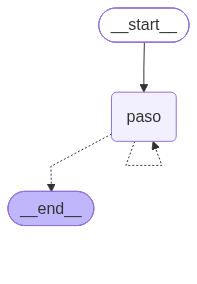

In [9]:
from IPython.display import Image, display

display(Image(newton.get_graph().draw_mermaid_png()))

`compile` revisa la estructura y devuelve el grafo ejecutable. Comprueba que haya una arista desde `START` y que cada arista salga de un vértice conocido y llegue a uno que existe. No comprueba que todos los nodos sean alcanzables ni que exista un camino a `END`, así que compilar no garantiza que la ejecución termine. El dibujo de `draw_mermaid_png` requiere internet, porque lo genera el servicio mermaid.ink.

El tercer argumento de `add_conditional_edges` declara la imagen de $c$, el conjunto $\{\texttt{paso}, \texttt{END}\}$. Es opcional: sin él el grafo se ejecuta igual. Pero si $c$ está anotada solo como `-> str`, LangGraph no puede deducir a dónde lleva y la descripción del grafo omite la arista `paso → paso`. Una anotación `-> Literal["paso", "__end__"]` también declara la imagen.

In [10]:
constructor = StateGraph(EstadoNewton)
constructor.add_node("paso", paso)
constructor.add_edge(START, "paso")
constructor.add_conditional_edges("paso", continuar)
sin_imagen = constructor.compile()


def aristas(grafo) -> list[str]:
    return sorted(
        f"{a.source} → {a.target}" + (" (condicional)" if a.conditional else "")
        for a in grafo.get_graph().edges
    )


print("con imagen:", aristas(newton))
print("sin imagen:", aristas(sin_imagen))
print("x final sin imagen:", sin_imagen.invoke({"x": 1.0, "n": 0})["x"])

con imagen: ['__start__ → paso', 'paso → __end__ (condicional)', 'paso → paso (condicional)']
sin imagen: ['__start__ → paso', 'paso → __end__']
x final sin imagen: 1.4142135623746899


## 6. Ejecución por supersteps

**Definición 1.8 (superstep).** La ejecución avanza en pasos discretos llamados supersteps, numerados desde 0.

- El superstep 0 es el de `START`: escribe la entrada $e$ y produce el estado inicial $s_0$.
- En el superstep $t \ge 1$, se activan los nodos que eligieron las aristas al cerrar el superstep $t - 1$. Cada nodo activo $v$ lee el mismo estado $s_{t-1}$ y calcula su actualización $\varphi_v(s_{t-1})$. Al cerrar el superstep se aplican las actualizaciones; con un solo nodo activo, $s_t = s_{t-1} \oplus \varphi_v(s_{t-1})$.

En este módulo hay un solo nodo activo por superstep. Con varios (módulo 4), todos leen el mismo $s_{t-1}$ y sus actualizaciones se combinan al cerrar el paso.

**Propiedad 1.9.** Una ejecución produce una sucesión de estados $s_0, s_1, s_2, \dots$, un estado por superstep. `stream` con `stream_mode="values"` entrega esa sucesión e `invoke` devuelve su último término.

**Observación.** La entrada también se aplica con $\oplus$: $s_0 = s_\varnothing \oplus e$, donde $s_\varnothing$ tiene en cada clave con reducer su valor inicial (la lista vacía, en una lista) y ninguna otra clave. Como $[\,]$ es neutro para la concatenación, aquí $s_0$ coincide con la entrada.

In [11]:
for s in newton.stream({"x": 1.0, "n": 0}, stream_mode="values"):
    print(s)

{'x': 1.0, 'n': 0}
{'x': 1.5, 'n': 1}
{'x': 1.4166666666666667, 'n': 2}
{'x': 1.4142156862745099, 'n': 3}
{'x': 1.4142135623746899, 'n': 4}


La misma sucesión, con el error $e_n = |x_n - \sqrt{2}|$ y el cociente $e_n / e_{n-1}^2$:

In [12]:
import math

anterior = None
for s in newton.stream({"x": 1.0, "n": 0}, stream_mode="values"):
    e = abs(s["x"] - math.sqrt(2))
    cociente = f"{e / anterior**2:.4f}" if anterior else "—"
    print(f"n = {s['n']}   x = {s['x']:.16f}   e = {e:.1e}   e_n/e_(n-1)² = {cociente}")
    anterior = e

print(f"\n1/(2√2) = {1 / (2 * math.sqrt(2)):.4f}")

n = 0   x = 1.0000000000000000   e = 4.1e-01   e_n/e_(n-1)² = —
n = 1   x = 1.5000000000000000   e = 8.6e-02   e_n/e_(n-1)² = 0.5000
n = 2   x = 1.4166666666666667   e = 2.5e-03   e_n/e_(n-1)² = 0.3333
n = 3   x = 1.4142156862745099   e = 2.1e-06   e_n/e_(n-1)² = 0.3529
n = 4   x = 1.4142135623746899   e = 1.6e-12   e_n/e_(n-1)² = 0.3535

1/(2√2) = 0.3536


**Teorema (convergencia cuadrática de Newton; resultado clásico, sin demostración aquí).** Si $f$ es de clase $C^2$, $r$ es una raíz con $f'(r) \ne 0$ y $x_0$ está suficientemente cerca de $r$, entonces

$$\lim_{n \to \infty} \frac{e_{n+1}}{e_n^2} = \left| \frac{f''(r)}{2 f'(r)} \right|.$$

Para $f(x) = x^2 - 2$ y $r = \sqrt{2}$, el límite es $\frac{2}{2 \cdot 2\sqrt{2}} = \frac{1}{2\sqrt{2}} \approx 0{,}3536$, y la tabla lo muestra desde $n = 3$. El error se aproxima al cuadrado del anterior por una constante, así que su exponente casi se duplica en cada paso. El ejercicio 3 estima ese orden. `invoke` entrega solo el último término:

In [13]:
newton.invoke({"x": 1.0, "n": 0})

{'x': 1.4142135623746899, 'n': 4}

## 7. Terminación

**Definición 1.10 (`recursion_limit`).** `recursion_limit` es la cantidad máxima de supersteps de una ejecución, contando el de `START`. Se pasa en la configuración: `invoke(entrada, {"recursion_limit": L})`. Si la ejecución necesita más, LangGraph la detiene con `GraphRecursionError`. En langgraph 1.2.17 vale 10 007 por defecto. El valor está en `langgraph/_internal/_config.py` y se cambia con la variable de entorno `LANGGRAPH_DEFAULT_RECURSION_LIMIT`.

**Proposición 1.11.** Sean $\varepsilon > 0$, $L$ el valor de `recursion_limit` y $(x_n)$ las iteradas que calcula el grafo de la sección 5, en punto flotante. Supóngase que $f'(x_k) \ne 0$ para cada iterada usada en un paso.

1. Si existe $n \ge 1$ con $|f(x_n)| < \varepsilon$ y el menor de ellos cumple $n + 1 \le L$, la ejecución llega a `END` en el superstep $n$.
2. Si no existe tal $n$, la ejecución nunca llega a `END`: `recursion_limit` la detiene con `GraphRecursionError`.

*Demostración.* La arista fija `START → paso` hace que el primer estado evaluado por $c$ sea $s_1$, y después de cada paso $c$ se evalúa en el estado nuevo. (1) Si $n$ es el menor índice con $|f(x_n)| < \varepsilon$, $c$ elige `paso` en $s_1, \dots, s_{n-1}$ y `END` en $s_n$. Eso usa los supersteps $0, \dots, n$, que son $n + 1 \le L$. (2) La única arista que llega a `END` es la condicional, y $c$ elige `END` solo cuando $|f(x_n)| < \varepsilon$. Si eso no ocurre nunca, $c$ elige `paso` en cada superstep hasta superar $L$. $\square$

Con $f(x) = x^2 + 1$, que no tiene raíces reales, ese $n$ no existe, y la ejecución se detiene con `GraphRecursionError`:

In [14]:
from langgraph.errors import GraphRecursionError


def construir_newton(g, dg, epsilon=EPSILON, cota=None):
    """Grafo de Newton para g. Con `cota`, llega a END después de a lo más `cota` pasos."""

    def paso(s: EstadoNewton) -> dict:
        x = s["x"]
        return {"x": x - g(x) / dg(x), "n": s["n"] + 1}

    def continuar(s: EstadoNewton) -> str:
        sigue = abs(g(s["x"])) >= epsilon
        if cota is not None:
            sigue = sigue and s["n"] < cota
        return "paso" if sigue else END

    constructor = StateGraph(EstadoNewton)
    constructor.add_node("paso", paso)
    constructor.add_edge(START, "paso")
    constructor.add_conditional_edges("paso", continuar, ["paso", END])
    return constructor.compile()


sin_raiz = construir_newton(lambda x: x**2 + 1, lambda x: 2 * x)
try:
    sin_raiz.invoke({"x": 0.5, "n": 0}, {"recursion_limit": 100})
except GraphRecursionError as error:
    print(type(error).__name__, "→", str(error).splitlines()[0])

GraphRecursionError → Recursion limit of 100 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.


Para $x^2 - 2$ desde $x_0 = 1$ hay 4 pasos de Newton más el superstep de `START`, así que el mínimo es $L = 5$:

In [15]:
for limite in (4, 5):
    try:
        newton.invoke({"x": 1.0, "n": 0}, {"recursion_limit": limite})
        print(f"recursion_limit = {limite}: llega a END")
    except GraphRecursionError:
        print(f"recursion_limit = {limite}: GraphRecursionError")

recursion_limit = 4: GraphRecursionError
recursion_limit = 5: llega a END


`recursion_limit` corta la ejecución con un error. Para que la ejecución termine por sí misma, la cota tiene que estar en la arista.

**Proposición 1.12.** Sea $N \ge 1$ y sea

$$c_N(s) = \begin{cases} \texttt{paso} & \text{si } |f(s(x))| \ge \varepsilon \text{ y } s(n) < N, \\ \texttt{END} & \text{si no.} \end{cases}$$

Supóngase que la entrada tiene $n = 0$, que $f'(x_k) \ne 0$ para cada iterada usada en un paso y que `recursion_limit` $\ge N + 1$. Entonces la ejecución llega a `END` después de a lo más $N$ pasos de Newton, es decir, en a lo más $N + 1$ supersteps.

*Demostración.* Cada superstep de `paso` aumenta $n$ en 1, así que después de $k$ pasos $s_k(n) = k$. Si $c_N$ no eligió `END` antes, en $s_N$ vale $s_N(n) = N$ y $c_N$ elige `END`. Eso ocurre en el superstep $N$, el número $N + 1$ contando el de `START`, y la hipótesis sobre `recursion_limit` asegura que se alcanza. $\square$

In [16]:
acotado = construir_newton(lambda x: x**2 + 1, lambda x: 2 * x, cota=50)
final = acotado.invoke({"x": 0.5, "n": 0})

print(final)
print("|f(x)| < ε:", abs(final["x"] ** 2 + 1) < EPSILON)

{'x': -0.8707527744354187, 'n': 50}
|f(x)| < ε: False


Llegar a `END` no implica converger. Con la cota, el estado final tiene que revisarse: aquí $n = N = 50$ y $|f(x_{50})| \ge \varepsilon$.

## Resumen

- Un **esquema** $(K, (V_k)_{k \in K})$ es un tipo y un **estado** es un elemento de $S = \prod_{k} V_k$. En LangGraph son un `TypedDict` y un `dict`. El `TypedDict` no valida tipos.
- Un **nodo** es una función $\varphi : S \to U$ que devuelve una actualización parcial.
- $s \oplus u$ aplica el reducer de cada clave de $\operatorname{dom}(u)$. Por defecto el valor nuevo reemplaza al anterior. Cada clave es un canal; en este módulo, `LastValue` o `BinaryOperatorAggregate`.
- Las **aristas** fijas y condicionales ($c : S \to V \setminus \{\texttt{START}\}$) definen qué vértice sigue. `add_conditional_edges` puede recibir la imagen de $c$. `compile` revisa la estructura, pero no garantiza que la ejecución termine.
- La ejecución avanza en **supersteps**: el 0 escribe la entrada y, con un nodo activo, $s_t = s_{t-1} \oplus \varphi(s_{t-1})$. `stream(..., stream_mode="values")` entrega la sucesión de estados e `invoke`, su último término.
- Un ciclo puede no terminar. `recursion_limit` acota los supersteps, `START` incluido, y vale 10 007 por defecto. Una cota en la arista garantiza llegar a `END`, pero no la convergencia.

## Ejercicios

**Ejercicio 1 (bisección).** Expresar el método de bisección como grafo: un estado con claves $a$, $b$ y $n$ que cumple $f(a)\,f(b) \le 0$, un nodo que reemplaza $a$ o $b$ por el punto medio y una arista condicional que termina cuando $b - a < \varepsilon$. Probarlo con $f(x) = x^2 - 2$ en $[1, 2]$ y determinar cuántos pasos hace.

*Pista:* el invariante $f(a)\,f(b) \le 0$ decide qué extremo se reemplaza.

<details>
<summary>Solución</summary>

```python
class EstadoBiseccion(TypedDict):
    a: float
    b: float
    n: int


def biseccion(s: EstadoBiseccion) -> dict:
    m = (s["a"] + s["b"]) / 2
    if f(s["a"]) * f(m) <= 0:
        return {"b": m, "n": s["n"] + 1}
    return {"a": m, "n": s["n"] + 1}


def seguir(s: EstadoBiseccion) -> str:
    return "biseccion" if s["b"] - s["a"] >= EPSILON else END


constructor = StateGraph(EstadoBiseccion)
constructor.add_node("biseccion", biseccion)
constructor.add_edge(START, "biseccion")
constructor.add_conditional_edges("biseccion", seguir, ["biseccion", END])
bisecar = constructor.compile()

bisecar.invoke({"a": 1.0, "b": 2.0, "n": 0})  # n = 34
```

El nodo devuelve solo el extremo que cambia, y la Propiedad 1.6 conserva el otro. A diferencia de Newton, la bisección llega a `END` sin cota: después de $n$ pasos, $b - a = 2^{-n}(b_0 - a_0)$, y la ejecución termina en el menor $n$ con $2^{-n}(b_0 - a_0) < \varepsilon$, que es $n = \lfloor \log_2((b_0 - a_0)/\varepsilon) \rfloor + 1 = \lfloor \log_2 10^{10} \rfloor + 1 = 34$. Esto vale en aritmética exacta; en punto flotante requiere además que $\varepsilon$ sea mayor que la distancia entre flotantes consecutivos en $[a, b]$.

</details>

**Ejercicio 2 (una clave olvidada).** En `construir_newton` con `cota=50`, cambiar `paso` para que devuelva solo `{"x": ...}`. Predecir qué ocurre con $f(x) = x^2 + 1$ antes de ejecutarlo.

*Pista:* Propiedad 1.6. ¿Qué valor tiene $n$ en cada superstep?

<details>
<summary>Solución</summary>

```python
def paso_sin_n(s: EstadoNewton) -> dict:
    x = s["x"]
    return {"x": x - (x**2 + 1) / (2 * x)}


def continuar_con_cota(s: EstadoNewton) -> str:
    sigue = abs(s["x"] ** 2 + 1) >= EPSILON and s["n"] < 50
    return "paso" if sigue else END


constructor = StateGraph(EstadoNewton)
constructor.add_node("paso", paso_sin_n)
constructor.add_edge(START, "paso")
constructor.add_conditional_edges("paso", continuar_con_cota, ["paso", END])

try:
    constructor.compile().invoke({"x": 0.5, "n": 0}, {"recursion_limit": 100})
except GraphRecursionError:
    print("GraphRecursionError: n se quedó en 0")
```

`n` no está en el dominio de la actualización, así que conserva el valor 0 en todos los estados y la condición $s(n) < N$ nunca falla. La Proposición 1.12 supone que cada paso aumenta $n$ en 1. Sin esa hipótesis la cota no actúa y vuelve el `GraphRecursionError`.

</details>

**Ejercicio 3 (orden de convergencia).** Guardar la trayectoria de Newton para $f(x) = x^2 - 2$ en una clave con reducer `operator.add` y estimar el orden de convergencia

$$p_n = \frac{\log(e_{n+1}/e_n)}{\log(e_n/e_{n-1})}, \qquad e_n = |x_n - \sqrt{2}|.$$

*Pista:* la trayectoria completa queda en el estado final, sin necesidad de `stream`.

<details>
<summary>Solución</summary>

```python
class EstadoNewtonTrayectoria(TypedDict):
    x: float
    n: int
    trayectoria: Annotated[list[float], operator.add]


def paso_con_trayectoria(s: EstadoNewtonTrayectoria) -> dict:
    x = s["x"] - f(s["x"]) / df(s["x"])
    return {"x": x, "n": s["n"] + 1, "trayectoria": [x]}


def continuar_trayectoria(s: EstadoNewtonTrayectoria) -> str:
    return "paso" if abs(f(s["x"])) >= EPSILON else END


constructor = StateGraph(EstadoNewtonTrayectoria)
constructor.add_node("paso", paso_con_trayectoria)
constructor.add_edge(START, "paso")
constructor.add_conditional_edges("paso", continuar_trayectoria, ["paso", END])
final = constructor.compile().invoke({"x": 1.0, "n": 0, "trayectoria": [1.0]})

e = [abs(x - math.sqrt(2)) for x in final["trayectoria"]]
[math.log(e[i + 1] / e[i]) / math.log(e[i] / e[i - 1]) for i in range(1, len(e) - 1)]
```

Los tres valores, $p_1 \approx 2{,}26$, $p_2 \approx 1{,}98$ y $p_3 \approx 2{,}00$, se acercan a 2: Newton converge con orden 2 hacia una raíz simple. Más iteraciones no mejoran la estimación, porque el error se estanca cerca de la precisión de la máquina ($\sim 10^{-16}$) y $p_n$ deja de ser informativo.

</details>

**Siguiente:** la lección 2 agrega mensajes, herramientas de SymPy y el modelo de lenguaje.